# Inspecting `vgrid__rolling_ridge` — the new HC-MAE champion

Headline: Δ_HC = −38.92 / win-rate 62.9 % vs lag-30 baseline. Full leaderboard below; the rest of the notebook inspects only the winning model — example curves, distribution of per-row HC-MAE, per-month breakdown.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from aemo_curves.metrics.hc_mae import curve_hc_mae_distance

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

REPO = Path('..').resolve()
RESULTS_CSV = REPO / 'experiments' / 'vgrid_30d_demand' / 'results.csv'
BEST_RUN = 'vgrid_d30d__rolling_ridge'
BASE_RUN = '30d__baseline_lag30_demand'

summary = pd.read_csv(RESULTS_CSV).sort_values('delta_mean').reset_index(drop=True)
print('Leaderboard under HC-MAE (lower delta_mean = better):')
print(summary.round(3).to_string(index=False))

Leaderboard under HC-MAE (lower delta_mean = better):
                           run     n  hc_mae_mean  hc_mae_median  baseline_hc_mae_mean  delta_mean  delta_median  win_rate
         vgrid__rolling_oracle 17232       26.608         22.837               171.539    -144.931      -124.146     0.959
          vgrid__static_oracle 17232       27.961         23.738               171.539    -143.578      -123.252     0.955
        interp__rolling_oracle 17232      100.885         85.250               171.539     -70.654       -54.358     0.690
         interp__static_oracle 17232      104.935         89.949               171.539     -66.604       -50.425     0.678
          vgrid__rolling_ridge 17232      132.621        108.543               171.539     -38.918       -30.781     0.629
              vgrid__strat_knn 17232      133.781        109.678               171.539     -37.758       -29.109     0.626
          same_weekday_avg_30d 17232      149.163        122.686               171.53

## Load best model + baseline predictions, score per row

In [2]:
MLRUNS = REPO / 'mlruns'
def find_run(name):
    for t in MLRUNS.glob('*/*/tags/experiment_name'):
        if t.read_text().strip() == name:
            return t.parent.parent
    raise FileNotFoundError(name)

best = pd.read_pickle(find_run(BEST_RUN) / 'artifacts' / 'result' / 'predictions.pkl')
base = pd.read_pickle(find_run(BASE_RUN) / 'artifacts' / 'result' / 'predictions.pkl')
for df in (best, base):
    df['Trading Date'] = pd.to_datetime(df['Trading Date'])
print(f'best ({BEST_RUN}): {len(best):,} rows')
print(f'baseline ({BASE_RUN}): {len(base):,} rows')

def _row(args):
    return curve_hc_mae_distance(args[0], args[1], args[2], args[3])

for df, lab in [(best, 'best'), (base, 'baseline')]:
    args = list(zip(df['true_curve_qty'], df['true_curve_price'],
                    df['pred_curve_qty'], df['pred_curve_price']))
    df['hc_mae'] = Parallel(n_jobs=-1)(delayed(_row)(a) for a in args)
    print(f'{lab}: HC-MAE mean={df["hc_mae"].mean():.2f}  median={df["hc_mae"].median():.2f}')

key = ['Trading Date', 'Interval Number']
merged = best.merge(
    base[key + ['hc_mae', 'pred_curve_qty', 'pred_curve_price']].rename(
        columns={'hc_mae': 'baseline_hc_mae',
                 'pred_curve_qty': 'base_curve_qty',
                 'pred_curve_price': 'base_curve_price'}),
    on=key, how='inner')
merged['delta_hc'] = merged['hc_mae'] - merged['baseline_hc_mae']
merged['win'] = merged['delta_hc'] < 0
print(f'\nmerged: {len(merged):,} rows  ·  mean Δ={merged["delta_hc"].mean():+.3f}  '
      f'·  win-rate={merged["win"].mean():.4f}')

best (vgrid_d30d__rolling_ridge): 17,232 rows
baseline (30d__baseline_lag30_demand): 17,232 rows
best: HC-MAE mean=132.62  median=108.54
baseline: HC-MAE mean=171.54  median=149.51

merged: 17,232 rows  ·  mean Δ=-38.918  ·  win-rate=0.6289


## Distribution of per-row HC-MAE and per-month Δ

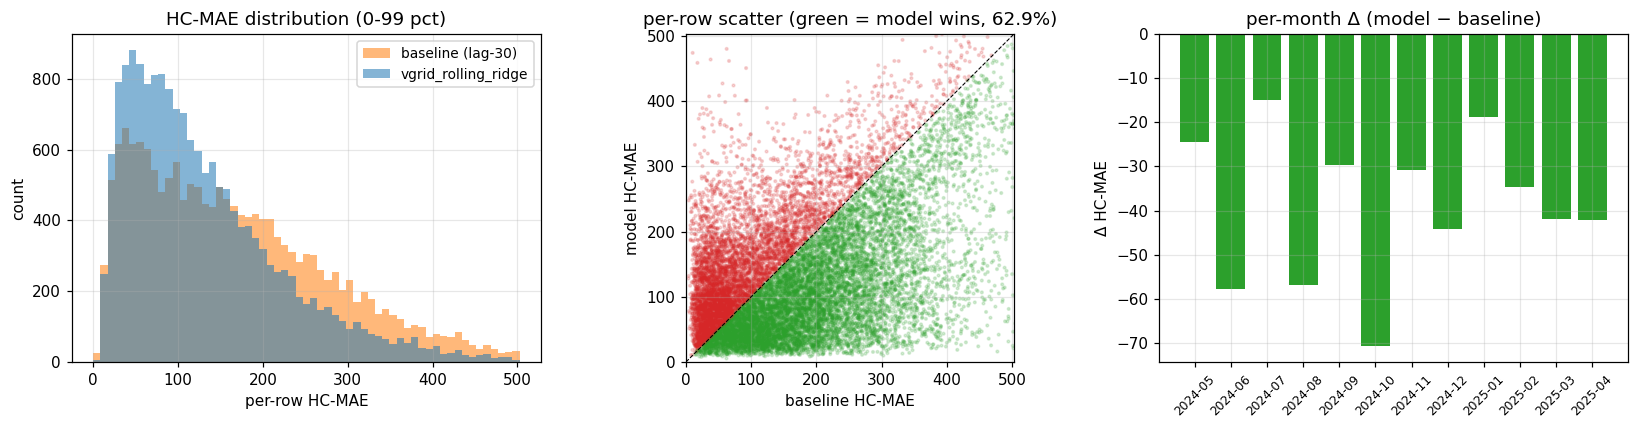


per-month summary:
  month  delta_mean  win_rate
2024-05     -24.495     0.533
2024-06     -57.836     0.724
2024-07     -14.924     0.538
2024-08     -56.884     0.776
2024-09     -29.684     0.656
2024-10     -70.809     0.689
2024-11     -30.884     0.628
2024-12     -44.249     0.644
2025-01     -18.773     0.521
2025-02     -34.731     0.577
2025-03     -42.015     0.611
2025-04     -42.106     0.655


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.linspace(0, np.quantile(np.r_[merged['hc_mae'], merged['baseline_hc_mae']], 0.99), 60)
axes[0].hist(merged['baseline_hc_mae'], bins=bins, alpha=0.55, label='baseline (lag-30)', color='C1')
axes[0].hist(merged['hc_mae'], bins=bins, alpha=0.55, label='vgrid_rolling_ridge', color='C0')
axes[0].set_xlabel('per-row HC-MAE'); axes[0].set_ylabel('count'); axes[0].legend(fontsize=9)
axes[0].set_title('HC-MAE distribution (0-99 pct)')

axes[1].scatter(merged['baseline_hc_mae'], merged['hc_mae'], s=3, alpha=0.18,
                c=np.where(merged['win'], 'C2', 'C3'))
lim = float(np.quantile(np.r_[merged['hc_mae'], merged['baseline_hc_mae']], 0.99))
axes[1].plot([0, lim], [0, lim], 'k--', lw=0.7)
axes[1].set_xlim(0, lim); axes[1].set_ylim(0, lim); axes[1].set_aspect('equal')
axes[1].set_xlabel('baseline HC-MAE'); axes[1].set_ylabel('model HC-MAE')
axes[1].set_title(f'per-row scatter (green = model wins, {merged["win"].mean():.1%})')

merged['month'] = merged['Trading Date'].dt.to_period('M').astype(str)
monthly = merged.groupby('month').agg(delta_mean=('delta_hc', 'mean'),
                                       win_rate=('win', 'mean')).reset_index()
x = np.arange(len(monthly))
axes[2].bar(x, monthly['delta_mean'],
            color=np.where(monthly['delta_mean'] < 0, 'C2', 'C3'))
axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_xticks(x); axes[2].set_xticklabels(monthly['month'], rotation=45, fontsize=8)
axes[2].set_ylabel('Δ HC-MAE'); axes[2].set_title('per-month Δ (model − baseline)')
plt.tight_layout(); plt.show()

print('\nper-month summary:')
print(monthly.round(3).to_string(index=False))

## Detailed Δ analysis — distribution of improvements, CDFs, cumulative gain

Δ HC-MAE quantiles  p05=-230.83  p25=-101.74  p50=-30.78  p75=+30.73  p95=+124.59
  mean Δ = -38.918  ·  trimmed5%-mean = -36.426


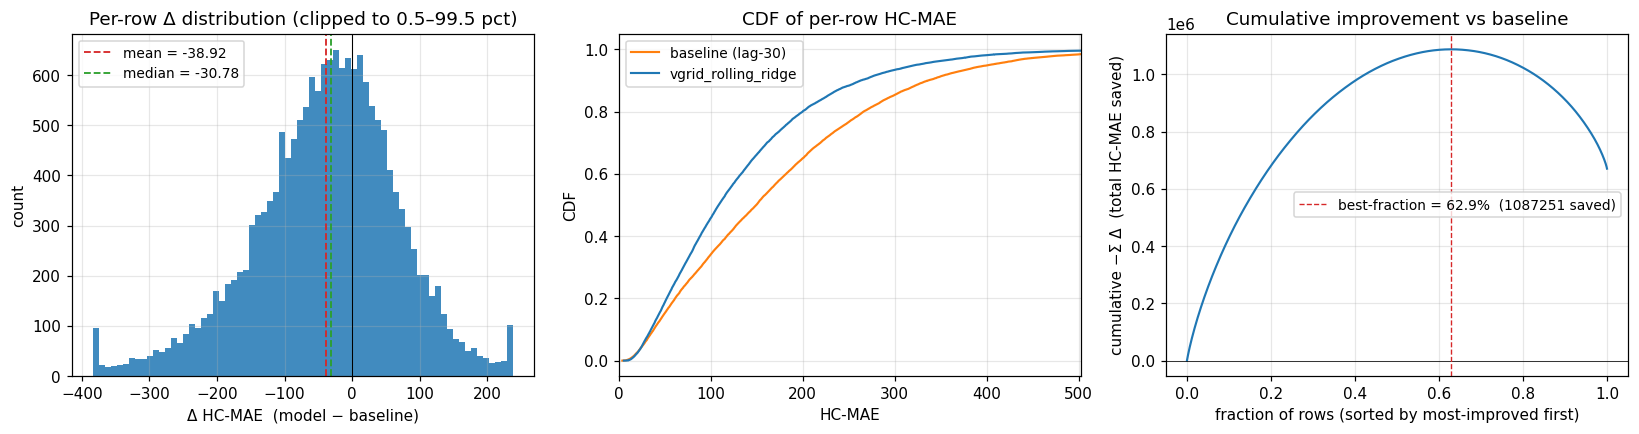

In [4]:
d = merged['delta_hc'].to_numpy()
qs = np.quantile(d, [0.05, 0.25, 0.5, 0.75, 0.95])
print(f'Δ HC-MAE quantiles  p05={qs[0]:+.2f}  p25={qs[1]:+.2f}  p50={qs[2]:+.2f}  '
      f'p75={qs[3]:+.2f}  p95={qs[4]:+.2f}')
print(f'  mean Δ = {d.mean():+.3f}  ·  trimmed5%-mean = {d[(d>=qs[0])&(d<=qs[4])].mean():+.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (1) histogram of per-row Δ with key reference lines
lo, hi = np.quantile(d, [0.005, 0.995])
axes[0].hist(d.clip(lo, hi), bins=70, color='C0', alpha=0.85)
axes[0].axvline(0, color='k', lw=0.7)
axes[0].axvline(d.mean(), color='C3', ls='--', lw=1.2, label=f'mean = {d.mean():+.2f}')
axes[0].axvline(np.median(d), color='C2', ls='--', lw=1.2, label=f'median = {np.median(d):+.2f}')
axes[0].set_xlabel('Δ HC-MAE  (model − baseline)'); axes[0].set_ylabel('count')
axes[0].set_title('Per-row Δ distribution (clipped to 0.5–99.5 pct)')
axes[0].legend(fontsize=9)

# (2) CDFs of model vs baseline HC-MAE
mb = merged['baseline_hc_mae'].to_numpy()
mm = merged['hc_mae'].to_numpy()
xb = np.sort(mb); xm = np.sort(mm)
y = np.arange(1, len(xb) + 1) / len(xb)
axes[1].plot(xb, y, color='C1', lw=1.4, label='baseline (lag-30)')
axes[1].plot(xm, y, color='C0', lw=1.4, label='vgrid_rolling_ridge')
axes[1].set_xlabel('HC-MAE'); axes[1].set_ylabel('CDF')
axes[1].set_xlim(0, np.quantile(np.r_[mb, mm], 0.99))
axes[1].set_title('CDF of per-row HC-MAE')
axes[1].legend(fontsize=9)

# (3) Cumulative gain — sort rows worst→best by Δ, plot cumulative sum
order = np.argsort(d)
cumgain = -np.cumsum(d[order])         # positive = total $ saved at this rank
frac = np.arange(1, len(d) + 1) / len(d)
axes[2].plot(frac, cumgain, lw=1.4, color='C0')
axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_xlabel('fraction of rows (sorted by most-improved first)')
axes[2].set_ylabel('cumulative −Σ Δ  (total HC-MAE saved)')
axes[2].set_title('Cumulative improvement vs baseline')
# annotate where cumgain peaks (best subset)
imax = int(np.argmax(cumgain))
axes[2].axvline(frac[imax], color='C3', ls='--', lw=0.9,
                label=f'best-fraction = {frac[imax]:.1%}  ({cumgain[imax]:.0f} saved)')
axes[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

## Per-interval, per-weekday, and interval×weekday heatmap

Where on the daily cycle and which weekdays does the model help most?

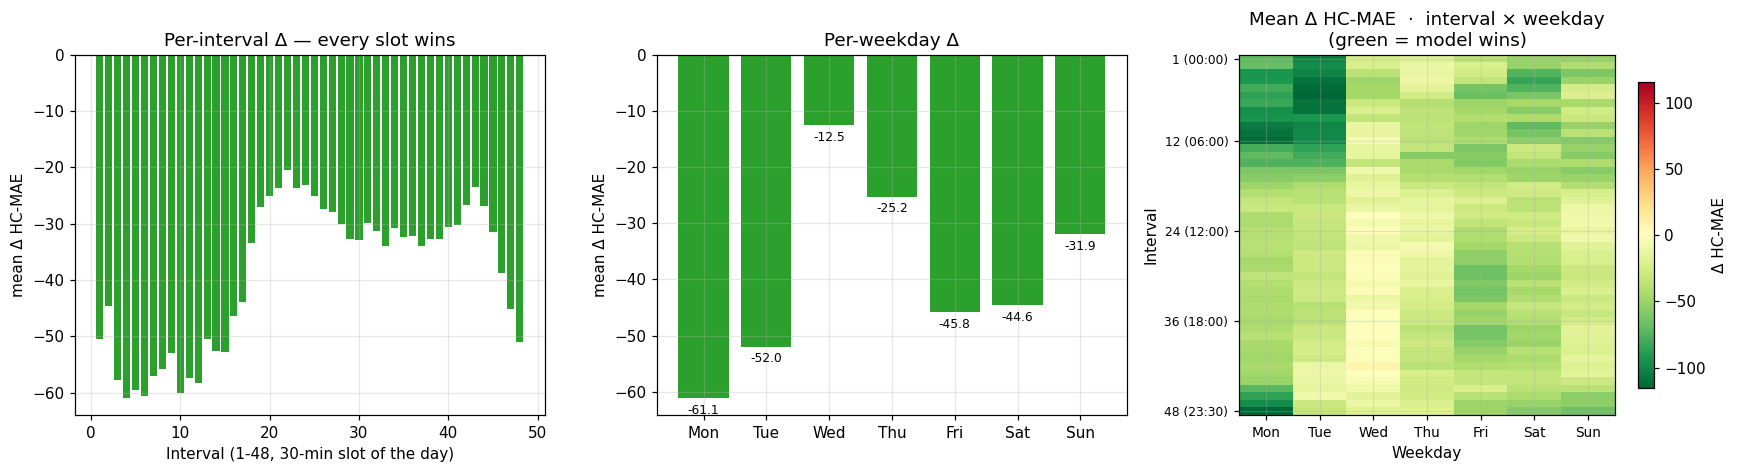


Weakest weekday: Wed (Δ=-12.55)
Strongest weekday: Mon (Δ=-61.13)


In [5]:
merged['dow'] = merged['Trading Date'].dt.dayofweek
dow_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

by_int = merged.groupby('Interval Number').agg(
    delta=('delta_hc', 'mean'), win=('win', 'mean')).reset_index()
by_dow = merged.groupby('dow').agg(
    delta=('delta_hc', 'mean'), win=('win', 'mean')).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# (1) per-interval Δ
axes[0].bar(by_int['Interval Number'], by_int['delta'],
            color=np.where(by_int['delta'] < 0, 'C2', 'C3'))
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_xlabel('Interval (1-48, 30-min slot of the day)')
axes[0].set_ylabel('mean Δ HC-MAE')
axes[0].set_title('Per-interval Δ — every slot wins')

# (2) per-weekday Δ
axes[1].bar(np.arange(7), by_dow['delta'],
            color=np.where(by_dow['delta'] < 0, 'C2', 'C3'))
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(dow_labels)
axes[1].set_ylabel('mean Δ HC-MAE')
axes[1].set_title('Per-weekday Δ')
for i, v in enumerate(by_dow['delta']):
    axes[1].text(i, v - 1, f'{v:+.1f}', ha='center', va='top', fontsize=8)

# (3) heatmap interval × weekday
pivot = (merged.groupby(['Interval Number', 'dow'])['delta_hc']
         .mean().unstack('dow'))
vmax = float(np.nanmax(np.abs(pivot.values)))
im = axes[2].imshow(pivot.values, aspect='auto', cmap='RdYlGn_r',
                    vmin=-vmax, vmax=vmax)
axes[2].set_yticks([0, 11, 23, 35, 47])
axes[2].set_yticklabels(['1 (00:00)', '12 (06:00)', '24 (12:00)',
                         '36 (18:00)', '48 (23:30)'], fontsize=8)
axes[2].set_xticks(range(7)); axes[2].set_xticklabels(dow_labels, fontsize=9)
axes[2].set_ylabel('Interval'); axes[2].set_xlabel('Weekday')
axes[2].set_title('Mean Δ HC-MAE  ·  interval × weekday\n(green = model wins)')
fig.colorbar(im, ax=axes[2], shrink=0.85, label='Δ HC-MAE')
plt.tight_layout(); plt.show()

# Strongest / weakest weekdays (no backslashes inside f-string expressions)
worst_dow = by_dow['delta'].idxmax()
best_dow = by_dow['delta'].idxmin()
worst_label = dow_labels[int(by_dow.iloc[worst_dow, 0])]
best_label = dow_labels[int(by_dow.iloc[best_dow, 0])]
worst_val = float(by_dow['delta'].iloc[worst_dow])
best_val = float(by_dow['delta'].iloc[best_dow])
print()
print(f'Weakest weekday: {worst_label} (Δ={worst_val:+.2f})')
print(f'Strongest weekday: {best_label} (Δ={best_val:+.2f})')

## Performance vs baseline difficulty — does the model help on hard cases?

Stratify the test rows by the baseline's HC-MAE (= "how hard was this row for lag-30?"), then plot the model's HC-MAE and win-rate per bin. A good metric-aware model should win *more* on the hard cases (high baseline HC-MAE), not less.

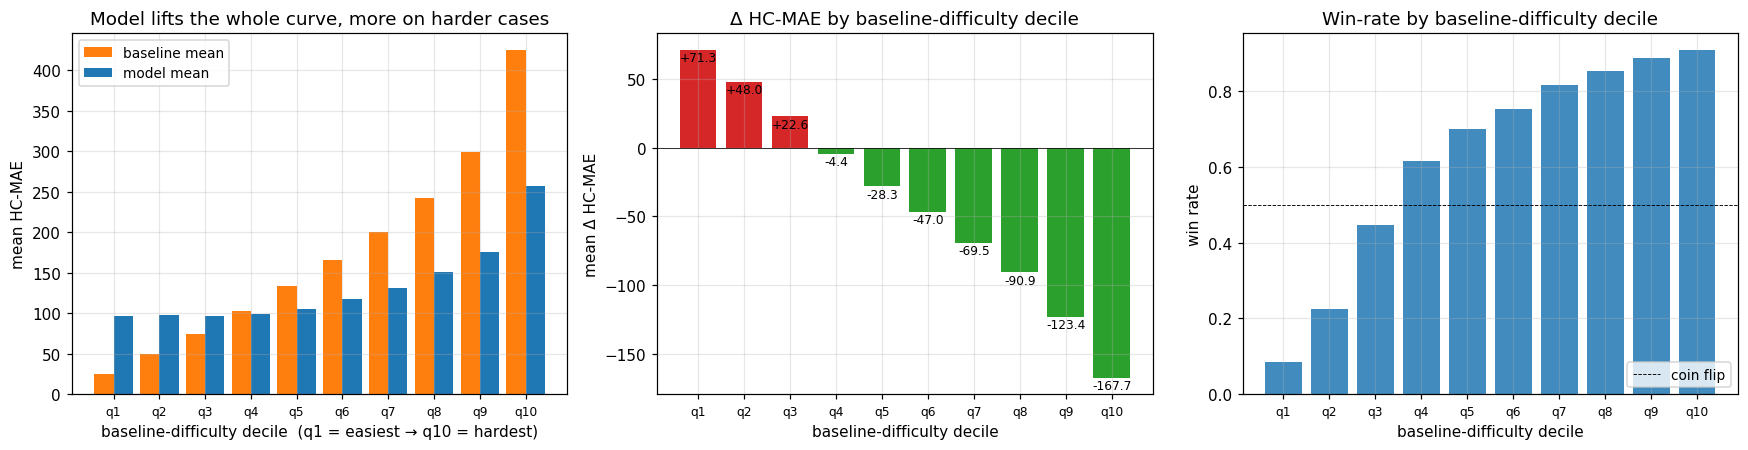


Per-difficulty decile summary:
 baseline_q  baseline_mean  model_mean    delta   win    n
          0         25.484      96.811   71.327 0.084 1724
          1         49.434      97.402   47.969 0.226 1723
          2         74.471      97.106   22.635 0.446 1723
          3        102.810      98.382   -4.428 0.615 1723
          4        133.062     104.752  -28.310 0.701 1723
          5        165.000     118.017  -46.984 0.753 1723
          6        199.996     130.544  -69.452 0.817 1723
          7        242.055     151.160  -90.896 0.853 1723
          8        298.723     175.352 -123.372 0.887 1723
          9        424.293     256.630 -167.663 0.908 1724


In [6]:
n_bins = 10
merged['baseline_q'] = pd.qcut(merged['baseline_hc_mae'], n_bins, labels=False, duplicates='drop')
by_q = merged.groupby('baseline_q').agg(
    baseline_mean=('baseline_hc_mae', 'mean'),
    model_mean=('hc_mae', 'mean'),
    delta=('delta_hc', 'mean'),
    win=('win', 'mean'),
    n=('hc_mae', 'size'),
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (1) model vs baseline mean within each baseline-difficulty decile
x = np.arange(len(by_q)); w = 0.42
axes[0].bar(x - w/2, by_q['baseline_mean'], w, color='C1', label='baseline mean')
axes[0].bar(x + w/2, by_q['model_mean'], w, color='C0', label='model mean')
axes[0].set_xticks(x); axes[0].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[0].set_xlabel('baseline-difficulty decile  (q1 = easiest → q10 = hardest)')
axes[0].set_ylabel('mean HC-MAE')
axes[0].set_title('Model lifts the whole curve, more on harder cases')
axes[0].legend(fontsize=9)

# (2) mean Δ per decile
axes[1].bar(x, by_q['delta'],
            color=np.where(by_q['delta'] < 0, 'C2', 'C3'))
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(x); axes[1].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[1].set_xlabel('baseline-difficulty decile')
axes[1].set_ylabel('mean Δ HC-MAE')
axes[1].set_title('Δ HC-MAE by baseline-difficulty decile')
for i, v in enumerate(by_q['delta']):
    axes[1].text(i, v - 1, f'{v:+.1f}', ha='center', va='top', fontsize=8)

# (3) win-rate per decile
axes[2].bar(x, by_q['win'], color='C0', alpha=0.85)
axes[2].axhline(0.5, color='k', lw=0.6, ls='--', label='coin flip')
axes[2].set_xticks(x); axes[2].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[2].set_xlabel('baseline-difficulty decile')
axes[2].set_ylabel('win rate')
axes[2].set_title('Win-rate by baseline-difficulty decile')
axes[2].legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.show()

print()
print('Per-difficulty decile summary:')
print(by_q.round(3).to_string(index=False))

## Per-month detail — mean, median, win-rate, and full Δ boxplot

The previous bar showed only the mean per month. A boxplot reveals the spread, the outliers, and whether the per-row Δ distribution stays consistently negative or just gets pulled down by tail wins.

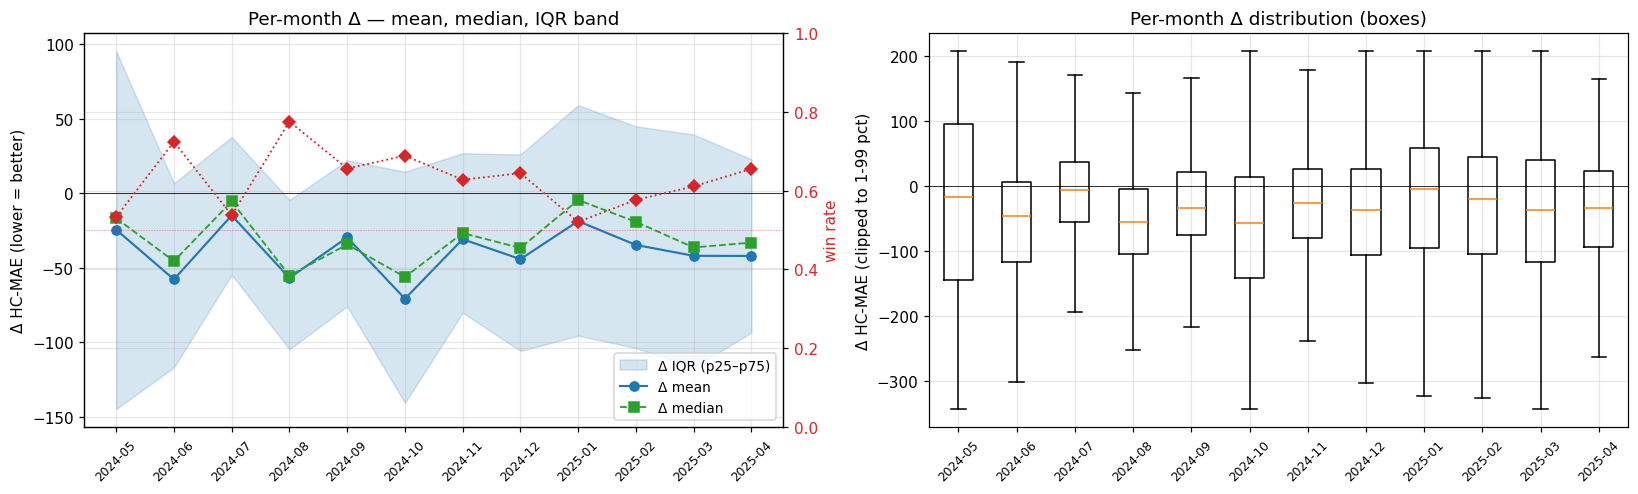


  month    n  delta_mean  delta_median  delta_p25  delta_p75  win_rate
2024-05 1488      -24.49        -16.79    -144.77      95.27      0.53
2024-06 1440      -57.84        -45.57    -116.80       6.63      0.72
2024-07 1488      -14.92         -5.59     -54.73      37.65      0.54
2024-08 1488      -56.88        -55.28    -104.72      -4.60      0.78
2024-09 1440      -29.68        -34.39     -75.87      22.05      0.66
2024-10 1488      -70.81        -56.20    -140.69      14.35      0.69
2024-11 1440      -30.88        -26.77     -80.12      26.77      0.63
2024-12 1488      -44.25        -36.77    -105.78      25.91      0.64
2025-01 1488      -18.77         -4.59     -95.54      59.00      0.52
2025-02 1344      -34.73        -19.23    -103.84      44.79      0.58
2025-03 1488      -42.01        -36.41    -116.67      39.33      0.61
2025-04 1152      -42.11        -33.15     -93.56      22.63      0.66


In [7]:
monthly_full = merged.groupby('month').agg(
    n=('delta_hc', 'size'),
    delta_mean=('delta_hc', 'mean'),
    delta_median=('delta_hc', 'median'),
    delta_p25=('delta_hc', lambda x: x.quantile(0.25)),
    delta_p75=('delta_hc', lambda x: x.quantile(0.75)),
    win_rate=('win', 'mean'),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
x = np.arange(len(monthly_full))

# (1) lines: mean Δ, median Δ, IQR band; secondary axis: win-rate
ax = axes[0]
ax.fill_between(x, monthly_full['delta_p25'], monthly_full['delta_p75'],
                color='C0', alpha=0.18, label='Δ IQR (p25–p75)')
ax.plot(x, monthly_full['delta_mean'], 'o-', color='C0', lw=1.4, label='Δ mean')
ax.plot(x, monthly_full['delta_median'], 's--', color='C2', lw=1.2, label='Δ median')
ax.axhline(0, color='k', lw=0.5)
ax.set_xticks(x); ax.set_xticklabels(monthly_full['month'], rotation=45, fontsize=8)
ax.set_ylabel('Δ HC-MAE (lower = better)')
ax.set_title('Per-month Δ — mean, median, IQR band')
ax.legend(loc='lower right', fontsize=9)

ax2 = ax.twinx()
ax2.plot(x, monthly_full['win_rate'], 'D:', color='C3', lw=1.2, label='win rate')
ax2.axhline(0.5, color='C3', lw=0.4, ls=':')
ax2.set_ylabel('win rate', color='C3'); ax2.set_ylim(0, 1.0)
ax2.tick_params(axis='y', labelcolor='C3')

# (2) boxplot of per-row Δ by month
data_by_month = [merged[merged['month'] == m]['delta_hc'].clip(lower=np.quantile(merged['delta_hc'], 0.01),
                                                               upper=np.quantile(merged['delta_hc'], 0.99))
                 for m in monthly_full['month']]
axes[1].boxplot(data_by_month, showfliers=False)
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(np.arange(1, len(monthly_full) + 1))
axes[1].set_xticklabels(monthly_full['month'], rotation=45, fontsize=8)
axes[1].set_ylabel('Δ HC-MAE (clipped to 1-99 pct)')
axes[1].set_title('Per-month Δ distribution (boxes)')
plt.tight_layout(); plt.show()

print()
print(monthly_full.round(2).to_string(index=False))

## Four random examples — actual / model / baseline

Black = true. Blue = `vgrid_rolling_ridge` prediction. Orange = lag-30 baseline. Re-run this cell for a fresh sample.

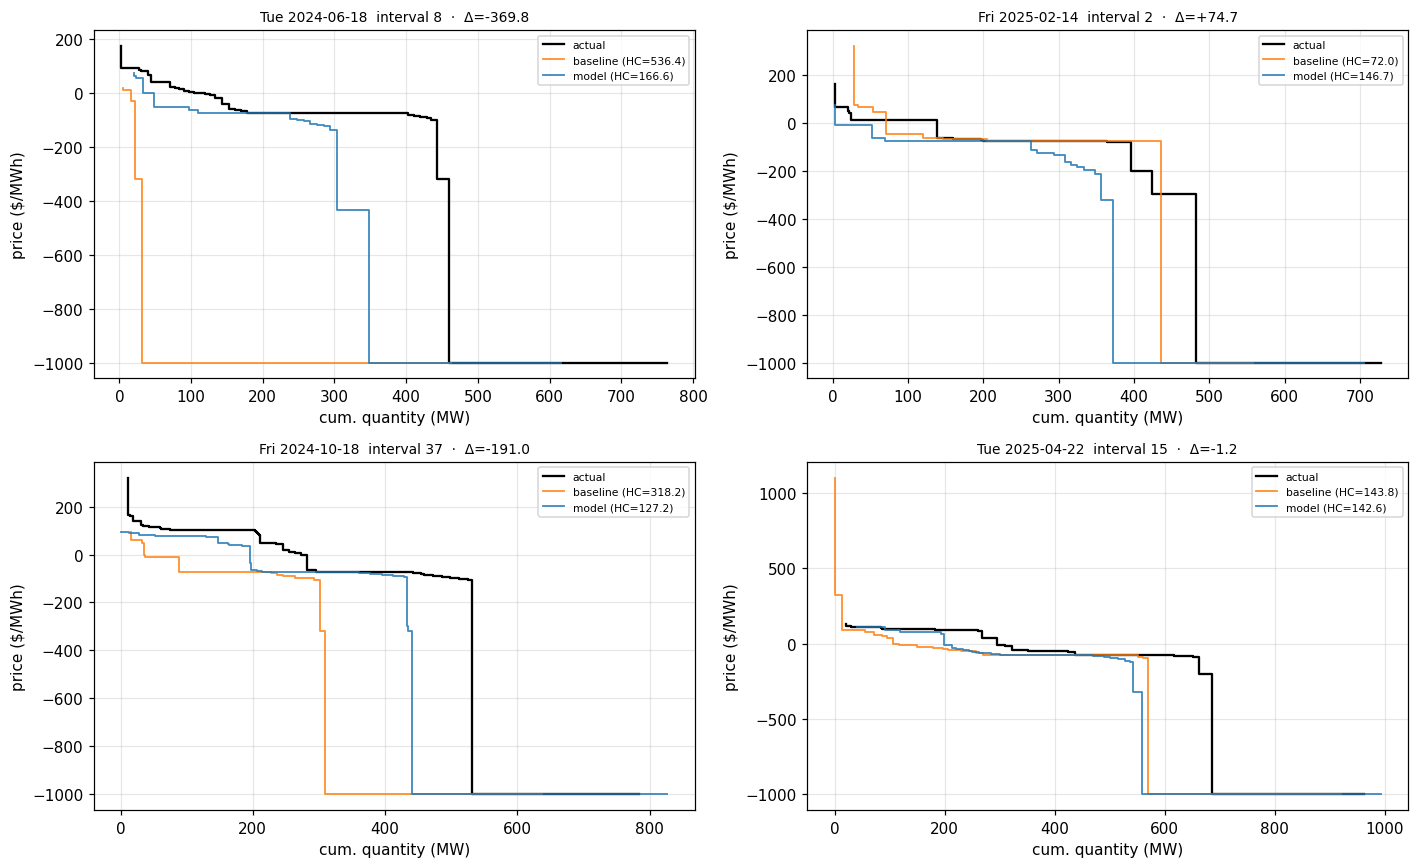

In [8]:
def plot_row(ax, r, title):
    ax.step(r['true_curve_qty'], r['true_curve_price'], where='pre', color='black', lw=1.5, label='actual')
    ax.step(r['base_curve_qty'], r['base_curve_price'], where='pre', color='C1', lw=1.2, alpha=0.85,
            label=f'baseline (HC={r["baseline_hc_mae"]:.1f})')
    ax.step(r['pred_curve_qty'], r['pred_curve_price'], where='pre', color='C0', lw=1.2, alpha=0.85,
            label=f'model (HC={r["hc_mae"]:.1f})')
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('cum. quantity (MW)'); ax.set_ylabel('price ($/MWh)')
    ax.legend(fontsize=7, loc='best')

rng = np.random.default_rng()
pick = merged.sample(4, random_state=rng.integers(1_000_000)).reset_index(drop=True)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (_, r) in zip(axes.flat, pick.iterrows()):
    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    plot_row(ax, r, f'{date_str}  interval {int(r["Interval Number"])}  ·  Δ={r["delta_hc"]:+.1f}')
plt.tight_layout(); plt.show()

## Three biggest wins (model ≫ baseline) and three biggest regressions (baseline ≫ model)

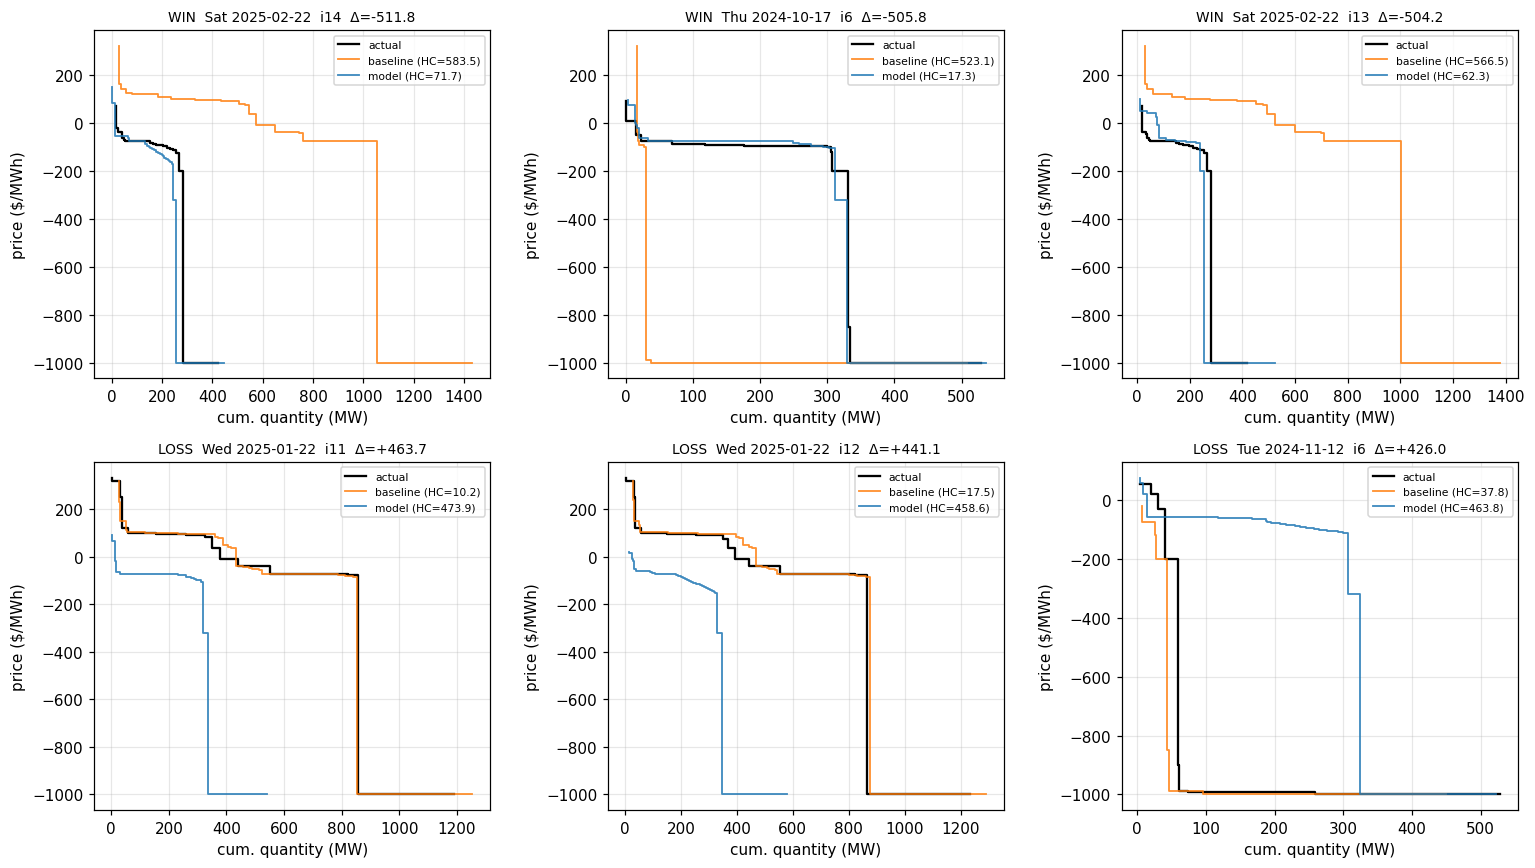

In [9]:
wins = merged.nsmallest(3, 'delta_hc').reset_index(drop=True)
losses = merged.nlargest(3, 'delta_hc').reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, (_, r) in enumerate(wins.iterrows()):
    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    plot_row(axes[0, col], r, f'WIN  {date_str}  i{int(r["Interval Number"])}  Δ={r["delta_hc"]:+.1f}')
for col, (_, r) in enumerate(losses.iterrows()):
    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    plot_row(axes[1, col], r, f'LOSS  {date_str}  i{int(r["Interval Number"])}  Δ={r["delta_hc"]:+.1f}')
plt.tight_layout(); plt.show()